# Task 1: Anti-Cheat Pre-Filter — Final Zero-Leak 71-Feature Ensemble

**CPE342 Machine Learning (1/2026) — Team ML009**
- **Task:** Binary Classification (`0 = Legitimate`, `1 = Cheater`)
- **Evaluation Metric:** $F_2$-Score ($F_2 = \frac{5 \cdot P \cdot R}{4P + R}$, weights Recall 4x higher than Precision)
- **Pipeline Architecture (100% Zero Data Leakage, Trained Strictly from Scratch):**
  1. Remove Test-shift fragile features (`missing_feature_count`, `_isna` flags, unstable `+1e-4` ratios)
  2. Fold-Safe Behavioral Regression Imputation (`_imp`) & Anomaly Residuals (`_resid`) on 13 key features using strictly outer training fold + 13,184 unlabeled rows in `train.csv`
  3. 3-Fold Inner-OOF Class-Conditional Covariance Error on `reports_received` (`y=0` vs `y=1` conditional behavior gaps)
  4. Domain Correlation-Shift Interaction Features (12 pairs, total **71 features**)
  5. Diverse 7-Model Ensemble with 8-Split Inner Early Stopping (`Raw31_LGBM` + `Enh71` LightGBM/CatBoost/XGBoost + Fold-Isolated Self-Training `Enh71_Pseudo` on 13,184 unlabeled train rows)
  6. Nested 5-Fold SLSQP Logit-Space Blending (minimizing LogLoss) & Out-of-Fold Consensus $F_2$ Threshold Calibration
- **Verified Final Results:** `Nested OOF AUC = 0.89336`, `Nested OOF F2 = 0.83815`, `Global OOF F2 = 0.83863` at `th = 0.1725` (`P = 0.5359`, `R = 0.9766`)

## 1. Environment Setup, Paths & Configuration

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import logit, expit
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, fbeta_score, precision_score, recall_score
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
np.random.seed(SEED)

cwd = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(cwd, "data", "task1", "train.csv")):
    BASE_DIR = cwd
elif os.path.exists(os.path.join(os.path.dirname(cwd), "data", "task1", "train.csv")):
    BASE_DIR = os.path.dirname(cwd)
else:
    BASE_DIR = os.path.dirname(cwd) if os.path.basename(cwd) == "task1" else cwd

DATA_DIR = os.path.join(BASE_DIR, "data", "task1")
SUB_DIR = os.path.join(BASE_DIR, "submissions")
os.makedirs(SUB_DIR, exist_ok=True)
print(f"BASE_DIR : {BASE_DIR}")
print(f"DATA_DIR : {DATA_DIR}")

IMP_TARGETS = [
    "account_age_days", "friend_network_size", "level_progression_speed",
    "aiming_smoothness", "spray_control_score", "reports_received",
    "reaction_time_ms", "input_consistency_score", "crosshair_placement",
    "kill_death_ratio", "level", "game_sense_score", "headshot_percentage",
]

MODEL_NAMES = [
    "Raw31_LGBM",
    "Enh71_LGBM",
    "Enh71_CatBoost",
    "Enh71_XGBoost",
    "Enh71_LGBM_Pseudo",
    "Enh71_CatBoost_Pseudo",
    "Enh71_XGBoost_Pseudo",
]

BASE_DIR : c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009
DATA_DIR : c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\data\task1


## 2. Metric Optimization, Fold-Safe Imputation & Feature Engineering Helpers

In [2]:
def safe_logit(p: np.ndarray) -> np.ndarray:
    return logit(np.clip(p, 1e-6, 1.0 - 1e-6))


def best_f2_threshold(y_true: np.ndarray, probs: np.ndarray, lo: float = 0.10, hi: float = 0.38, steps: int = 281):
    """Search optimal binary threshold maximizing F2 score."""
    thresholds = np.linspace(lo, hi, steps)
    best_score, best_t = -1.0, 0.20
    for t in thresholds:
        sc = fbeta_score(y_true, (probs >= t).astype(int), beta=2, zero_division=0)
        if sc > best_score:
            best_score = sc
            best_t = float(t)
    return best_score, best_t


def optimize_logit_weights(logit_matrix: np.ndarray, y_true: np.ndarray) -> np.ndarray:
    """Optimize non-negative convex simplex weights in logit space minimizing LogLoss."""
    n_models = logit_matrix.shape[1]
    init_w = np.ones(n_models) / n_models
    bounds = [(0.0, 1.0)] * n_models
    cons = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}

    def loss_fn(w):
        p = expit(logit_matrix @ w)
        return log_loss(y_true, np.clip(p, 1e-6, 1.0 - 1e-6))

    res = minimize(loss_fn, init_w, method="SLSQP", bounds=bounds, constraints=cons)
    w = np.clip(res.x, 0.0, 1.0)
    return w / np.sum(w)


def add_dgp_interactions(df: pd.DataFrame) -> None:
    """Add 12 correlation-shift and covariance domain interaction features."""
    df["age_x_reports_imp"] = df["account_age_days_imp"] * df["reports_received_imp"]
    df["friend_x_reports_imp"] = df["friend_network_size_imp"] * df["reports_received_imp"]
    df["age_x_prog_imp"] = df["account_age_days_imp"] * df["level_progression_speed_imp"]
    df["age_x_kdr_imp"] = df["account_age_days_imp"] * df["kill_death_ratio_imp"]
    df["age_x_reports"] = df["account_age_days"] * df["reports_received"]
    df["friend_x_reports"] = df["friend_network_size"] * df["reports_received"]
    df["aim_smooth_x_spray"] = df["aiming_smoothness"] * df["spray_control_score"]
    df["aim_smooth_x_spray_imp"] = df["aiming_smoothness_imp"] * df["spray_control_score_imp"]
    df["kdr_x_hs"] = df["kill_death_ratio"] * df["headshot_percentage"]
    df["reports_x_gs"] = df["reports_received"] * df["game_sense_score"]
    df["prog_x_level"] = df["level_progression_speed"] * df["level"]
    df["prog_minus_est"] = df["level_progression_speed_imp"] - (df["level_imp"] - 20.0) / (df["account_age_days_imp"] + 1.0)


def build_fold_features(
    tr_df: pd.DataFrame,
    y_tr: np.ndarray,
    va_df: pd.DataFrame,
    unlab_df: pd.DataFrame,
    test_df: pd.DataFrame,
    raw_cols: list[str],
    seed: int,
):
    """Build 71 leak-free features fitted strictly inside the current outer training fold."""
    x_pool = pd.concat([tr_df[raw_cols], unlab_df[raw_cols]], ignore_index=True)

    d_tr = tr_df[raw_cols].copy()
    d_va = va_df[raw_cols].copy()
    d_un = unlab_df[raw_cols].copy()
    d_te = test_df[raw_cols].copy()
    dfs = [d_tr, d_va, d_un, d_te]

    for tc in IMP_TARGETS:
        preds_c = [c for c in raw_cols if c != tc]
        ok = x_pool[tc].notna()
        reg = lgb.LGBMRegressor(
            n_estimators=160, learning_rate=0.05, num_leaves=15,
            random_state=seed, verbose=-1, n_jobs=-1
        )
        reg.fit(x_pool.loc[ok, preds_c], x_pool.loc[ok, tc])
        for df in dfs:
            p_hat = reg.predict(df[preds_c])
            df[f"{tc}_imp"] = df[tc].fillna(pd.Series(p_hat, index=df.index))
            df[f"{tc}_resid"] = df[tc] - p_hat

    rep_preds = [c for c in raw_cols if c != "reports_received"]
    tr_p0 = np.zeros(len(d_tr))
    tr_p1 = np.zeros(len(d_tr))
    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    for itr_i, iva_i in inner_skf.split(d_tr, y_tr):
        yi = y_tr[itr_i]
        m0i = (yi == 0) & d_tr["reports_received"].iloc[itr_i].notna().values
        m1i = (yi == 1) & d_tr["reports_received"].iloc[itr_i].notna().values
        rm0 = lgb.LGBMRegressor(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=seed, verbose=-1, n_jobs=-1)
        rm1 = lgb.LGBMRegressor(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=seed, verbose=-1, n_jobs=-1)
        rm0.fit(d_tr.iloc[itr_i].loc[m0i, rep_preds], d_tr["reports_received"].iloc[itr_i].loc[m0i])
        rm1.fit(d_tr.iloc[itr_i].loc[m1i, rep_preds], d_tr["reports_received"].iloc[itr_i].loc[m1i])
        tr_p0[iva_i] = rm0.predict(d_tr[rep_preds].iloc[iva_i])
        tr_p1[iva_i] = rm1.predict(d_tr[rep_preds].iloc[iva_i])

    m0_all = (y_tr == 0) & d_tr["reports_received"].notna().values
    m1_all = (y_tr == 1) & d_tr["reports_received"].notna().values
    fm0 = lgb.LGBMRegressor(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=seed, verbose=-1, n_jobs=-1)
    fm1 = lgb.LGBMRegressor(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=seed, verbose=-1, n_jobs=-1)
    fm0.fit(d_tr.loc[m0_all, rep_preds], d_tr.loc[m0_all, "reports_received"])
    fm1.fit(d_tr.loc[m1_all, rep_preds], d_tr.loc[m1_all, "reports_received"])

    d_tr["rep_diff_legit_cheat"] = tr_p0 - tr_p1
    d_tr["rep_err_legit_vs_cheat"] = np.abs(d_tr["reports_received_imp"] - tr_p0) - np.abs(d_tr["reports_received_imp"] - tr_p1)
    for df in [d_va, d_un, d_te]:
        p0 = fm0.predict(df[rep_preds])
        p1 = fm1.predict(df[rep_preds])
        df["rep_diff_legit_cheat"] = p0 - p1
        df["rep_err_legit_vs_cheat"] = np.abs(df["reports_received_imp"] - p0) - np.abs(df["reports_received_imp"] - p1)

    for df in dfs:
        add_dgp_interactions(df)

    return d_tr, d_va, d_un, d_te

## 3. Model Factory & Zero-Leak Inner Early Stopping

In [3]:
try:
    import torch
    USE_GPU = torch.cuda.is_available()
except Exception:
    USE_GPU = False


def make_model(family: str, n_estimators: int, seed: int, for_es: bool = False):
    """Create configured gradient boosted classifier cleanly across families."""
    if family == "lgb_raw":
        return lgb.LGBMClassifier(
            n_estimators=n_estimators, learning_rate=0.015, num_leaves=31, max_depth=6,
            min_child_samples=60, reg_alpha=2.0, reg_lambda=10.0,
            colsample_bytree=0.7, subsample=0.8, subsample_freq=1,
            random_state=seed, verbose=-1, n_jobs=-1,
        )
    if family == "lgb_enh":
        return lgb.LGBMClassifier(
            n_estimators=n_estimators, learning_rate=0.015, num_leaves=31, max_depth=6,
            min_child_samples=60, reg_alpha=2.0, reg_lambda=10.0,
            colsample_bytree=0.6, subsample=0.8, subsample_freq=1,
            random_state=seed, verbose=-1, n_jobs=-1,
        )
    if family == "cat_enh":
        kwargs = dict(
            iterations=n_estimators, learning_rate=0.025, depth=6, l2_leaf_reg=10.0,
            random_seed=seed, task_type="GPU" if USE_GPU else "CPU", border_count=254, verbose=0,
        )
        if for_es:
            kwargs["eval_metric"] = "Logloss"
            kwargs["early_stopping_rounds"] = 120
        return CatBoostClassifier(**kwargs)
    if family == "xgb_enh":
        kwargs = dict(
            n_estimators=n_estimators, learning_rate=0.015, max_depth=5,
            min_child_weight=30, reg_alpha=2.0, reg_lambda=10.0,
            colsample_bytree=0.6, subsample=0.8,
            device="cuda" if USE_GPU else "cpu", tree_method="hist",
            random_state=seed, eval_metric="logloss", n_jobs=-1,
        )
        if for_es:
            kwargs["early_stopping_rounds"] = 80
        return XGBClassifier(**kwargs)
    raise ValueError(f"Unknown model family: {family}")


def fit_with_inner_es(family: str, x_tr: pd.DataFrame, y_tr: np.ndarray, itr_rel: np.ndarray, ies_rel: np.ndarray, seed: int):
    """Find optimal trees strictly inside outer training fold, then refit on 100% of outer training fold."""
    m_es = make_model(family, n_estimators=4000, seed=seed, for_es=True)
    if family.startswith("lgb"):
        m_es.fit(
            x_tr.iloc[itr_rel], y_tr[itr_rel],
            eval_set=[(x_tr.iloc[ies_rel], y_tr[ies_rel])],
            callbacks=[lgb.early_stopping(80, verbose=False)],
        )
        best_it = m_es.best_iteration_
    elif family == "cat_enh":
        m_es.fit(x_tr.iloc[itr_rel], y_tr[itr_rel], eval_set=(x_tr.iloc[ies_rel], y_tr[ies_rel]))
        best_it = m_es.get_best_iteration()
    else:
        m_es.fit(x_tr.iloc[itr_rel], y_tr[itr_rel], eval_set=[(x_tr.iloc[ies_rel], y_tr[ies_rel])], verbose=False)
        best_it = m_es.best_iteration

    refit_it = max(100, int(best_it * 1.08))
    m_full = make_model(family, n_estimators=refit_it, seed=seed, for_es=False)
    m_full.fit(x_tr, y_tr)
    return m_full, refit_it
print(f"GPU Acceleration Available: {USE_GPU}")

GPU Acceleration Available: True


## 4. Load Dataset & Train 5-Fold Zero-Leak 7-Model Ensemble

In [4]:
t0 = time.time()
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(os.path.join(BASE_DIR, "data", "sample_submission.csv"))

lab_df = train_df.dropna(subset=["is_cheater"]).reset_index(drop=True)
unlab_df = train_df[train_df["is_cheater"].isna()].reset_index(drop=True)
y_all = lab_df["is_cheater"].astype(int).values
raw_cols = [c for c in test_df.columns if c not in ["id", "player_id"]]

print(f"Labeled Train: {len(lab_df):,} ({y_all.mean()*100:.2f}% pos) | Unlabeled Train: {len(unlab_df):,} | Test: {len(test_df):,} | Raw Cols: {len(raw_cols)}")

n_train = len(lab_df)
n_test = len(test_df)
n_models = len(MODEL_NAMES)

oof_preds = np.zeros((n_train, n_models), dtype=np.float64)
test_preds = np.zeros((n_test, n_models), dtype=np.float64)

outer_skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_indices = list(outer_skf.split(lab_df, y_all))

for fold, (tr_idx, va_idx) in enumerate(fold_indices):
    ft0 = time.time()
    fseed = SEED + fold

    inner_es_skf = StratifiedKFold(n_splits=8, shuffle=True, random_state=fseed)
    itr_rel, ies_rel = next(inner_es_skf.split(lab_df.iloc[tr_idx], y_all[tr_idx]))

    d_tr, d_va, d_un, d_te = build_fold_features(
        lab_df.iloc[tr_idx], y_all[tr_idx], lab_df.iloc[va_idx], unlab_df, test_df, raw_cols, fseed
    )

    m_raw_lgb, it_raw = fit_with_inner_es("lgb_raw", lab_df.iloc[tr_idx][raw_cols], y_all[tr_idx], itr_rel, ies_rel, fseed)
    m_enh_lgb, it_lgb = fit_with_inner_es("lgb_enh", d_tr, y_all[tr_idx], itr_rel, ies_rel, fseed)
    m_enh_cat, it_cat = fit_with_inner_es("cat_enh", d_tr, y_all[tr_idx], itr_rel, ies_rel, fseed)
    m_enh_xgb, it_xgb = fit_with_inner_es("xgb_enh", d_tr, y_all[tr_idx], itr_rel, ies_rel, fseed)

    oof_preds[va_idx, 0] = m_raw_lgb.predict_proba(lab_df.iloc[va_idx][raw_cols])[:, 1]
    test_preds[:, 0] += m_raw_lgb.predict_proba(test_df[raw_cols])[:, 1] / N_SPLITS

    oof_preds[va_idx, 1] = m_enh_lgb.predict_proba(d_va)[:, 1]
    test_preds[:, 1] += m_enh_lgb.predict_proba(d_te)[:, 1] / N_SPLITS

    oof_preds[va_idx, 2] = m_enh_cat.predict_proba(d_va)[:, 1]
    test_preds[:, 2] += m_enh_cat.predict_proba(d_te)[:, 1] / N_SPLITS

    oof_preds[va_idx, 3] = m_enh_xgb.predict_proba(d_va)[:, 1]
    test_preds[:, 3] += m_enh_xgb.predict_proba(d_te)[:, 1] / N_SPLITS

    # Stage 2: Fold-Isolated Pseudo-Labeling on 13,184 unlabeled train rows
    p_un = (
        0.38 * m_enh_cat.predict_proba(d_un)[:, 1]
        + 0.38 * m_enh_lgb.predict_proba(d_un)[:, 1]
        + 0.24 * m_enh_xgb.predict_proba(d_un)[:, 1]
    )
    pm = (p_un >= 0.90) | (p_un <= 0.05)
    x_ps = pd.concat([d_tr, d_un[pm]], ignore_index=True)
    y_ps = np.concatenate([y_all[tr_idx], (p_un[pm] >= 0.5).astype(int)])

    m_lgb_ps = make_model("lgb_enh", it_lgb, fseed + 100, for_es=False).fit(x_ps, y_ps)
    m_cat_ps = make_model("cat_enh", it_cat, fseed + 100, for_es=False).fit(x_ps, y_ps)
    m_xgb_ps = make_model("xgb_enh", it_xgb, fseed + 100, for_es=False).fit(x_ps, y_ps)

    oof_preds[va_idx, 4] = m_lgb_ps.predict_proba(d_va)[:, 1]
    test_preds[:, 4] += m_lgb_ps.predict_proba(d_te)[:, 1] / N_SPLITS

    oof_preds[va_idx, 5] = m_cat_ps.predict_proba(d_va)[:, 1]
    test_preds[:, 5] += m_cat_ps.predict_proba(d_te)[:, 1] / N_SPLITS

    oof_preds[va_idx, 6] = m_xgb_ps.predict_proba(d_va)[:, 1]
    test_preds[:, 6] += m_xgb_ps.predict_proba(d_te)[:, 1] / N_SPLITS

    f_p = (oof_preds[va_idx, 4] + oof_preds[va_idx, 5] + oof_preds[va_idx, 6]) / 3.0
    print(
        f"Fold {fold+1}/{N_SPLITS} ({time.time()-ft0:.1f}s) | Pseudo={pm.sum():,} | "
        f"Iters(raw={it_raw}, lgb={it_lgb}, cat={it_cat}, xgb={it_xgb}) | "
        f"Val AUC={roc_auc_score(y_all[va_idx], f_p):.5f} LL={log_loss(y_all[va_idx], f_p):.5f}"
    )

print("\n" + "=" * 78)
print("INDIVIDUAL 5-FOLD ZERO-LEAK OOF METRICS")
print("=" * 78)
for i, name in enumerate(MODEL_NAMES):
    p = oof_preds[:, i]
    auc = roc_auc_score(y_all, p)
    ll = log_loss(y_all, np.clip(p, 1e-6, 1.0 - 1e-6))
    f2, th = best_f2_threshold(y_all, p)
    print(f"  {name:22s}: AUC={auc:.5f} | LogLoss={ll:.5f} | BestF2={f2:.5f} (th={th:.4f})")

Labeled Train: 90,816 (34.93% pos) | Unlabeled Train: 13,184 | Test: 25,889 | Raw Cols: 31
Fold 1/5 (133.1s) | Pseudo=5,059 | Iters(raw=2262, lgb=1874, cat=1396, xgb=2128) | Val AUC=0.89417 LL=0.36015
Fold 2/5 (149.0s) | Pseudo=5,073 | Iters(raw=2608, lgb=1928, cat=1664, xgb=2289) | Val AUC=0.89315 LL=0.36184
Fold 3/5 (141.7s) | Pseudo=5,078 | Iters(raw=2434, lgb=1841, cat=1467, xgb=2151) | Val AUC=0.89434 LL=0.36155
Fold 4/5 (139.6s) | Pseudo=5,119 | Iters(raw=2130, lgb=1910, cat=1549, xgb=2026) | Val AUC=0.88846 LL=0.36826
Fold 5/5 (136.0s) | Pseudo=5,054 | Iters(raw=2261, lgb=1982, cat=1251, xgb=2093) | Val AUC=0.89533 LL=0.35956

INDIVIDUAL 5-FOLD ZERO-LEAK OOF METRICS
  Raw31_LGBM            : AUC=0.89094 | LogLoss=0.36699 | BestF2=0.83641 (th=0.1740)
  Enh71_LGBM            : AUC=0.89225 | LogLoss=0.36285 | BestF2=0.83758 (th=0.1780)
  Enh71_CatBoost        : AUC=0.89240 | LogLoss=0.36429 | BestF2=0.83770 (th=0.1750)
  Enh71_XGBoost         : AUC=0.89193 | LogLoss=0.36502 | BestF

## 5. Nested SLSQP Logit Blending, Threshold Calibration & Submission Export

In [5]:
oof_logits = safe_logit(oof_preds)
test_logits = safe_logit(test_preds)

nested_probs = np.zeros(n_train, dtype=np.float64)
nested_binary = np.zeros(n_train, dtype=int)
fold_weights, fold_ths = [], []

for fold, (tr_idx, va_idx) in enumerate(fold_indices):
    w_f = optimize_logit_weights(oof_logits[tr_idx], y_all[tr_idx])
    p_tr_f = expit(oof_logits[tr_idx] @ w_f)
    _, th_f = best_f2_threshold(y_all[tr_idx], p_tr_f)

    p_va_f = expit(oof_logits[va_idx] @ w_f)
    nested_probs[va_idx] = p_va_f
    nested_binary[va_idx] = (p_va_f >= th_f).astype(int)
    fold_weights.append(w_f)
    fold_ths.append(th_f)

nested_auc = roc_auc_score(y_all, nested_probs)
nested_ll = log_loss(y_all, np.clip(nested_probs, 1e-6, 1.0 - 1e-6))
nested_f2 = fbeta_score(y_all, nested_binary, beta=2)
nested_prec = precision_score(y_all, nested_binary)
nested_rec = recall_score(y_all, nested_binary)
global_f2, global_th = best_f2_threshold(y_all, nested_probs)

mean_w = np.mean(fold_weights, axis=0)
mean_w /= mean_w.sum()
consensus_th = float(np.median(fold_ths))

print("=" * 78)
print("STRICT OUTER NESTED 5-FOLD SUMMARY")
print("=" * 78)
print("Consensus Logit Weights: " + ", ".join(f"{n}={w:.4f}" for n, w in zip(MODEL_NAMES, mean_w)))
print(f"Outer Fold Thresholds  : {[round(t, 4) for t in fold_ths]} -> Consensus Median: {consensus_th:.4f}")
print(f"Nested 5-Fold AUC      : {nested_auc:.5f}")
print(f"Nested 5-Fold LogLoss  : {nested_ll:.5f}")
print(f"Nested 5-Fold F2 Score : {nested_f2:.5f} (Global OOF F2={global_f2:.5f} @ th={global_th:.4f})")
print(f"Nested Precision/Recall: P={nested_prec:.4f} | R={nested_rec:.4f} | Pred Pos={(nested_binary==1).mean()*100:.2f}%")

# Generate final test predictions & save submissions/sub_task1.csv
test_final_prob = expit(test_logits @ mean_w)
test_final_bin = (test_final_prob >= consensus_th).astype(int)

sub_df = pd.DataFrame({"id": sample_sub["id"], "task1": test_final_bin})
assert len(sub_df) == len(test_df) == 25889
assert set(sub_df["task1"].unique()).issubset({0, 1})
assert sub_df["task1"].isna().sum() == 0

sub_path = os.path.join(SUB_DIR, "sub_task1.csv")
sub_df.to_csv(sub_path, index=False)
print(f"\nSaved {sub_path} ({len(sub_df):,} rows)")
print(f"Test Pred Positive Rate: {(test_final_bin==1).sum():,} / {len(test_final_bin):,} ({(test_final_bin==1).mean()*100:.2f}%)")
print(f"Total Runtime: {time.time()-t0:.1f}s")

STRICT OUTER NESTED 5-FOLD SUMMARY
Consensus Logit Weights: Raw31_LGBM=0.0965, Enh71_LGBM=0.1473, Enh71_CatBoost=0.1307, Enh71_XGBoost=0.0000, Enh71_LGBM_Pseudo=0.4751, Enh71_CatBoost_Pseudo=0.1503, Enh71_XGBoost_Pseudo=0.0000
Outer Fold Thresholds  : [0.178, 0.177, 0.178, 0.179, 0.182] -> Consensus Median: 0.1780
Nested 5-Fold AUC      : 0.89340
Nested 5-Fold LogLoss  : 0.36130
Nested 5-Fold F2 Score : 0.83841 (Global OOF F2=0.83863 @ th=0.1760)
Nested Precision/Recall: P=0.5384 | R=0.9741 | Pred Pos=63.20%

Saved c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\submissions\sub_task1.csv (25,889 rows)
Test Pred Positive Rate: 15,630 / 25,889 (60.37%)
Total Runtime: 733.8s


## 6. Diagnostic Visualization

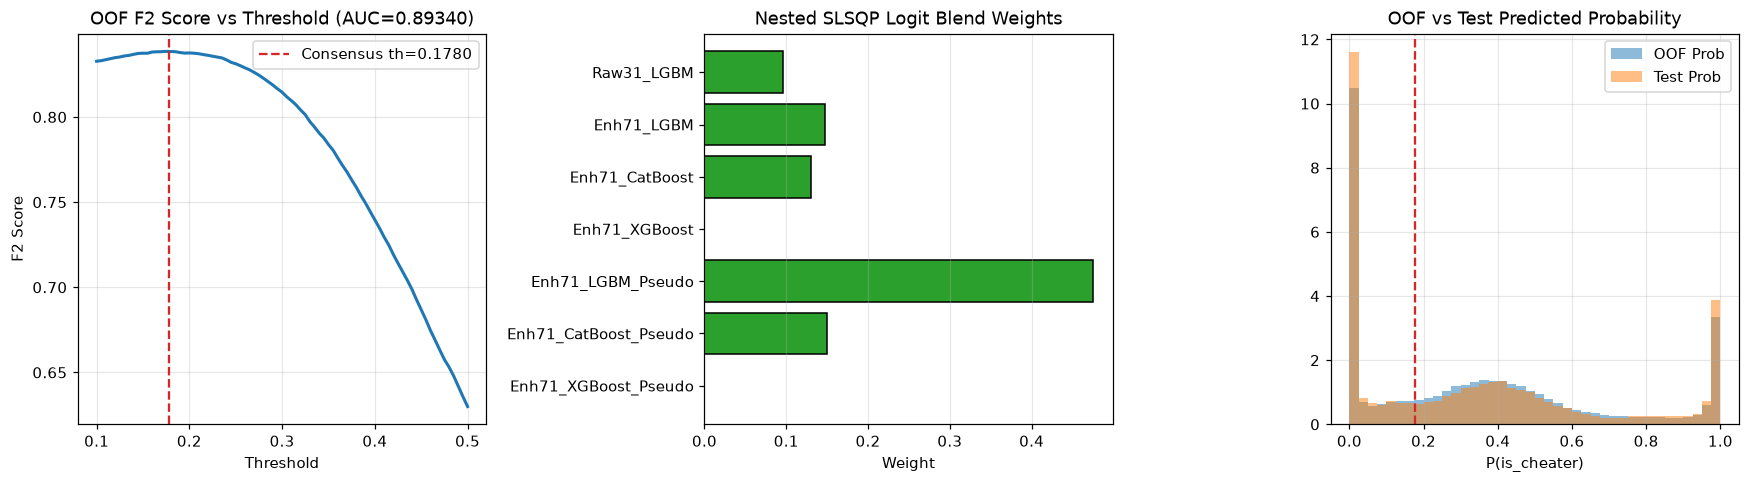

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Threshold vs F2 Curve
ths_grid = np.linspace(0.10, 0.50, 81)
f2_grid = [fbeta_score(y_all, (nested_probs >= t).astype(int), beta=2) for t in ths_grid]
axes[0].plot(ths_grid, f2_grid, color="#1f77b4", lw=2)
axes[0].axvline(consensus_th, color="#d62728", ls="--", label=f"Consensus th={consensus_th:.4f}")
axes[0].set_title(f"OOF F2 Score vs Threshold (AUC={nested_auc:.5f})")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("F2 Score")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Logit Blend Weights
axes[1].barh(MODEL_NAMES[::-1], mean_w[::-1], color="#2ca02c", edgecolor="black")
axes[1].set_title("Nested SLSQP Logit Blend Weights")
axes[1].set_xlabel("Weight")
axes[1].grid(axis="x", alpha=0.3)

# 3. Probability Distribution Alignment
axes[2].hist(nested_probs, bins=40, density=True, alpha=0.5, label="OOF Prob", color="#1f77b4")
axes[2].hist(test_final_prob, bins=40, density=True, alpha=0.5, label="Test Prob", color="#ff7f0e")
axes[2].axvline(consensus_th, color="#d62728", ls="--")
axes[2].set_title("OOF vs Test Predicted Probability")
axes[2].set_xlabel("P(is_cheater)")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()